# Evidencia visual · Etapas 1 a 4 · Reto OT Consulting
**Valeria López · A01352599 · Soporte analítico para la toma de decisiones (Gpo 301) · Equipo 3**

Este cuaderno junta en un solo lugar la evidencia técnica de las primeras cuatro etapas del reto:
exploración de las fuentes, calidad de datos, integridad entre tablas, validación de nómina,
transformación de la matriz de habilidades, indicadores calculados sobre las tablas acondicionadas y
el modelo dimensional lógico.

Fuentes del repositorio:
- `docs/Archive (3).zip`: los 8 Excel originales de OT Consulting.
- `docs/datos csv reto/clean_*.csv`: tablas acondicionadas con SQL en MySQL Workbench (etapa 3).

Cada gráfica también se guarda en `docs/img/` para usarla en la presentación.

In [1]:
import zipfile, io, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path('..')
ZIP = RAIZ / 'docs' / 'Archive (3).zip'
CLEAN = RAIZ / 'docs' / 'datos csv reto'
IMG = RAIZ / 'docs' / 'img'
IMG.mkdir(parents=True, exist_ok=True)

AZUL, AMBAR, ROJO, VERDE, GRIS = '#2563eb', '#f59e0b', '#dc2626', '#16a34a', '#94a3b8'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'font.size': 10})

def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(IMG / f'{nombre}.png', dpi=160, bbox_inches='tight')
    plt.show()

# Excel originales, leídos directo del zip
raw = {}
with zipfile.ZipFile(ZIP) as z:
    for n in z.namelist():
        if n.endswith('.xlsx') and not n.startswith('__MACOSX'):
            raw[Path(n).stem] = pd.read_excel(io.BytesIO(z.read(n)))

# Tablas acondicionadas
def leer_clean(nombre):
    df = pd.read_csv(CLEAN / f'clean_{nombre}.csv')
    df.columns = [re.sub(r'[^\w]', '', c) for c in df.columns]   # quita espacios invisibles
    return df

clean = {n: leer_clean(n) for n in ['colaboradores', 'asignaciones', 'clientes', 'departamentos',
                                     'roles', 'habilidades', 'matriz', 'activos']}
sorted(raw)

['Asignaciones_Colaboradores',
 'Catalogo_Activos',
 'Catalogo_Clientes',
 'Catalogo_Colaboradores',
 'Catalogo_Departamentos',
 'Catalogo_Habilidades',
 'Catalogo_Roles',
 'Matriz_Habilidades']

## Etapa 1 y 2 · Inventario de las fuentes
OT Consulting entregó 8 archivos de Excel con **459 registros** y **176 columnas** en total.
La matriz de habilidades es la más ancha (77 columnas) aunque solo tiene 54 filas.

Total registros: 459 · Total columnas: 176


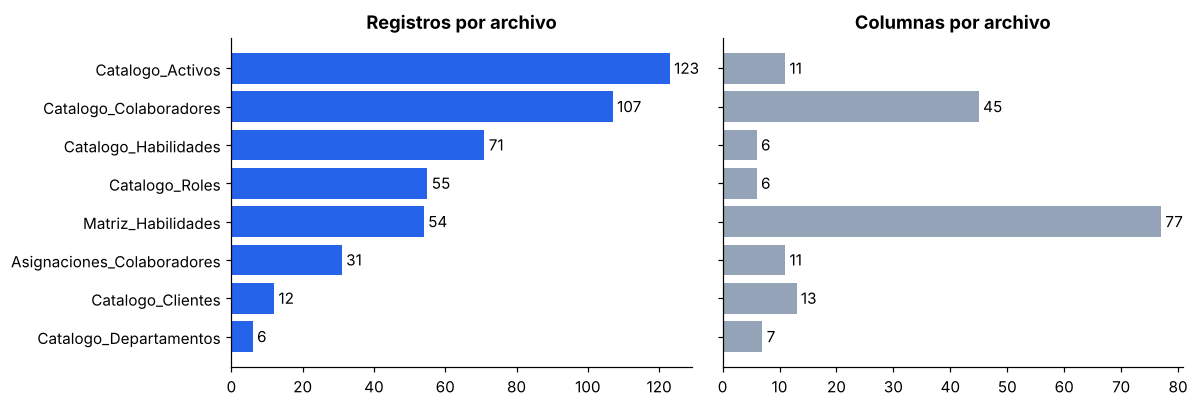

In [2]:
inv = pd.DataFrame({'archivo': list(raw), 'registros': [len(d) for d in raw.values()],
                    'columnas': [d.shape[1] for d in raw.values()]}).sort_values('registros')
print('Total registros:', inv.registros.sum(), '· Total columnas:', inv.columnas.sum())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
ax[0].barh(inv.archivo, inv.registros, color=AZUL)
ax[1].barh(inv.archivo, inv.columnas, color=GRIS)
for a, col, t in [(ax[0], 'registros', 'Registros por archivo'), (ax[1], 'columnas', 'Columnas por archivo')]:
    a.set_title(t)
    for y, v in enumerate(inv[col]): a.text(v, y, f' {v}', va='center')
guardar(fig, '01_inventario_fuentes')

## Etapa 2 · Calidad de datos: faltantes reales y disfrazados
Además de los nulos, cuento los **vacíos disfrazados**: "Pendiente", "N/A", "NULL", "-", la fecha de relleno
1990-01-01 y valores de prueba como 999999999. Pandas no los detecta como nulos, pero son datos faltantes.

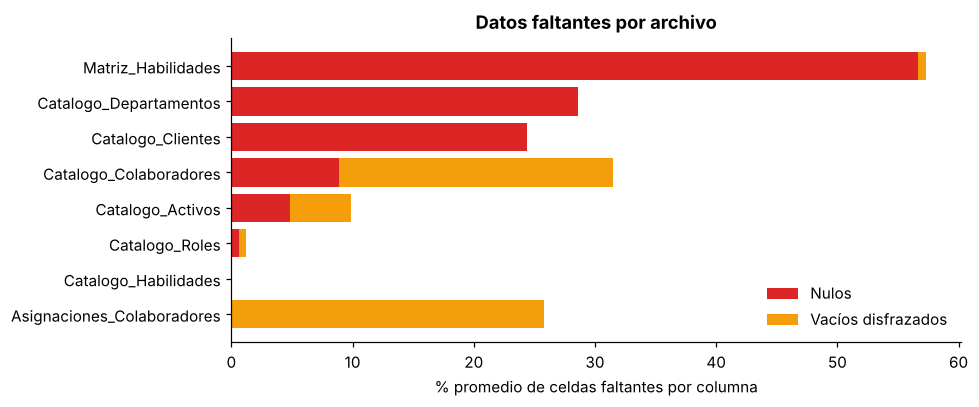

,nulos,disfrazados
archivo,,
Asignaciones_Colaboradores,0.0,25.8
Catalogo_Habilidades,0.0,0.0
Catalogo_Roles,0.6,0.6
Catalogo_Activos,4.8,5.0
Catalogo_Colaboradores,8.9,22.6
Catalogo_Clientes,24.4,0.0
Catalogo_Departamentos,28.6,0.0
Matriz_Habilidades,56.7,0.7


In [3]:
DISFRAZ = {'pendiente', 'n/a', 'na', 'null', '-', '', 'indefinido', 'sin asignar', '999999999'}

def es_disfrazado(s):
    t = s.astype(str).str.strip().str.lower()
    return s.notna() & (t.isin(DISFRAZ) | t.str.startswith('1990-01-01'))

perfil = []
for arch, d in raw.items():
    for col in d.columns:
        perfil.append({'archivo': arch, 'columna': col,
                       'nulos': d[col].isna().mean() * 100,
                       'disfrazados': es_disfrazado(d[col]).mean() * 100})
perfil = pd.DataFrame(perfil)
perfil['faltante_total'] = perfil.nulos + perfil.disfrazados

resumen = perfil.groupby('archivo')[['nulos', 'disfrazados']].mean().sort_values('nulos')
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(resumen.index, resumen.nulos, color=ROJO, label='Nulos')
ax.barh(resumen.index, resumen.disfrazados, left=resumen.nulos, color=AMBAR, label='Vacíos disfrazados')
ax.set_xlabel('% promedio de celdas faltantes por columna')
ax.set_title('Datos faltantes por archivo')
ax.legend(frameon=False, loc='lower right')
guardar(fig, '02_faltantes_por_archivo')
resumen.round(1)

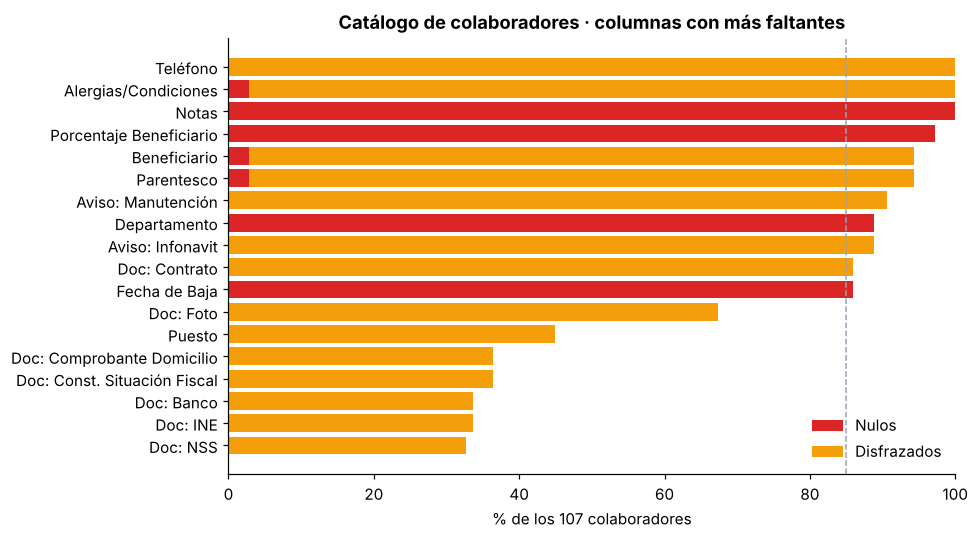

In [4]:
col = perfil[perfil.archivo == 'Catalogo_Colaboradores'].sort_values('faltante_total', ascending=False).head(18)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(col.columna, col.nulos, color=ROJO, label='Nulos')
ax.barh(col.columna, col.disfrazados, left=col.nulos, color=AMBAR, label='Disfrazados')
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.axvline(85, color=GRIS, ls='--', lw=1)
ax.set_xlabel('% de los 107 colaboradores'); ax.set_title('Catálogo de colaboradores · columnas con más faltantes')
ax.legend(frameon=False, loc='lower right')
guardar(fig, '03_faltantes_colaboradores')

In [5]:
asig, colab = raw['Asignaciones_Colaboradores'], raw['Catalogo_Colaboradores']
hallazgos = pd.Series({
    'Asignaciones sin rol (de 31)': es_disfrazado(asig['Rol Asignado']).sum() + asig['Rol Asignado'].isna().sum(),
    'Asignaciones con fin "Indefinido" o vacío': (asig['Fecha Fin'].astype(str).str.lower().str.contains('indefinido') | asig['Fecha Fin'].isna()).sum(),
    'Colaboradores con puesto pendiente': es_disfrazado(colab['Puesto']).sum() + colab['Puesto'].isna().sum(),
    'Activos con sueldo integrado en cero': ((colab['Estatus'] == 'Activo') & (pd.to_numeric(colab['Sueldo Total Integrado'], errors='coerce').fillna(0) == 0)).sum(),
})
hallazgos.to_frame('registros')

,registros
Asignaciones sin rol (de 31),29
"Asignaciones con fin ""Indefinido"" o vacío",24
Colaboradores con puesto pendiente,48
Activos con sueldo integrado en cero,5


## Etapa 2 · Integridad entre archivos
Las tablas no se relacionan por ID sino por **nombres escritos a mano**. Reviso cuántos nombres de Activos y
Asignaciones sí existen en el catálogo, cuántos colaboradores tienen matriz de habilidades y cuántos equipos
siguen con personas dadas de baja.

Equipos asignados a personas dadas de baja: 17


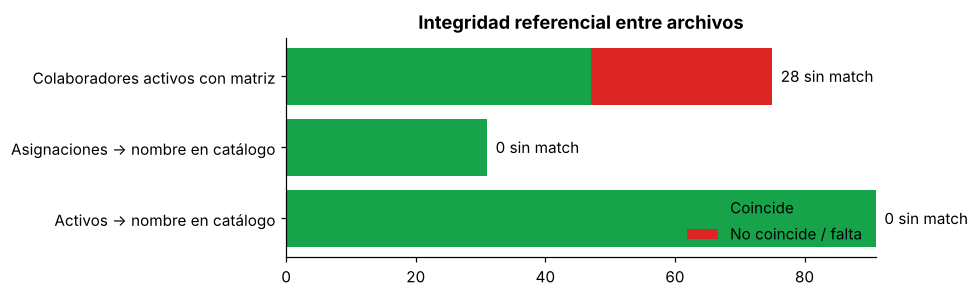

,coincide,no coincide / falta
Activos → nombre en catálogo,91,0
Asignaciones → nombre en catálogo,31,0
Colaboradores activos con matriz,47,28


In [6]:
norm = lambda s: s.astype(str).str.strip().str.upper()
nombres = set(norm(colab['Nombre Completo']))
estatus = dict(zip(norm(colab['Nombre Completo']), colab['Estatus']))
act = raw['Catalogo_Activos']
asignado = act['Colaborador Asignado']
con_persona = asignado.notna() & ~es_disfrazado(asignado)

matriz = raw['Matriz_Habilidades']
ids_matriz = set(matriz['ID Colaborador'].astype(str).str.strip())
activos_ids = set(colab.loc[colab.Estatus == 'Activo', 'ID'].astype(str))

integ = pd.DataFrame({
    'coincide': [norm(asignado[con_persona]).isin(nombres).sum(), norm(asig['Nombre Colaborador']).isin(nombres).sum(),
                 len(activos_ids & ids_matriz)],
    'no coincide / falta': [(~norm(asignado[con_persona]).isin(nombres)).sum(), (~norm(asig['Nombre Colaborador']).isin(nombres)).sum(),
                            len(activos_ids - ids_matriz)],
}, index=['Activos → nombre en catálogo', 'Asignaciones → nombre en catálogo', 'Colaboradores activos con matriz'])

baja_con_equipo = norm(asignado[con_persona]).map(estatus).eq('Baja').sum()
print('Equipos asignados a personas dadas de baja:', baja_con_equipo)

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.barh(integ.index, integ['coincide'], color=VERDE, label='Coincide')
ax.barh(integ.index, integ['no coincide / falta'], left=integ['coincide'], color=ROJO, label='No coincide / falta')
for y, (a, b) in enumerate(integ.values): ax.text(a + b, y, f'  {b} sin match', va='center')
ax.set_title('Integridad referencial entre archivos'); ax.legend(frameon=False, loc='lower right')
guardar(fig, '04_integridad')
integ

## Etapa 2 · Validación de nómina
Comprobé la regla de cálculo: **Neto total = Neto IMSS + Asimilados/Sindicato + Complementos** y
**Integrado = Neto total + Comisión + Impuestos IMSS**. Los puntos fuera de la diagonal o en cero son registros a revisar.

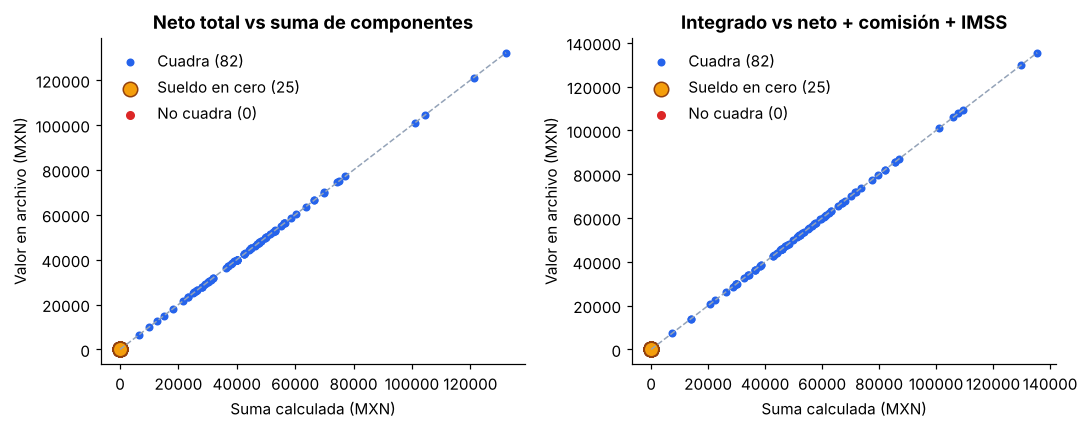

Registros con sueldo integrado en cero: 25


In [7]:
num = lambda c: pd.to_numeric(colab[c], errors='coerce').fillna(0)
suma_neto = num('Sueldo Neto IMSS') + num('Sueldo Asimilados/Sindicato') + num('Sueldo Complementos')
suma_int = num('Sueldo Neto Total') + num('Comisión Nómina') + num('Impuestos IMSS')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, x, y, t in [(ax[0], suma_neto, num('Sueldo Neto Total'), 'Neto total vs suma de componentes'),
                   (ax[1], suma_int, num('Sueldo Total Integrado'), 'Integrado vs neto + comisión + IMSS')]:
    ok = np.isclose(x, y, atol=1); cero = (y == 0)
    a.scatter(x[ok & ~cero], y[ok & ~cero], s=18, color=AZUL, label=f'Cuadra ({(ok & ~cero).sum()})')
    a.scatter(x[cero], y[cero], s=90, color=AMBAR, edgecolor='#92400e', label=f'Sueldo en cero ({cero.sum()})')
    a.scatter(x[~ok], y[~ok], s=24, color=ROJO, label=f'No cuadra ({(~ok).sum()})')
    m = max(x.max(), y.max()); a.plot([0, m], [0, m], color=GRIS, ls='--', lw=1)
    a.set_title(t); a.set_xlabel('Suma calculada (MXN)'); a.set_ylabel('Valor en archivo (MXN)'); a.legend(frameon=False)
guardar(fig, '05_validacion_nomina')
print('Registros con sueldo integrado en cero:', (num('Sueldo Total Integrado') == 0).sum())

## Etapa 3 · Transformación de la matriz de habilidades (unpivot)
La matriz original tiene **una columna por habilidad** (54 × 77). La convertimos a formato largo:
un registro por colaborador, habilidad y nivel. Las celdas vacías se descartan.

Antes: 54 filas × 77 columnas = 3,834 celdas de habilidad
Después: 1,529 registros (colaborador, habilidad, nivel)


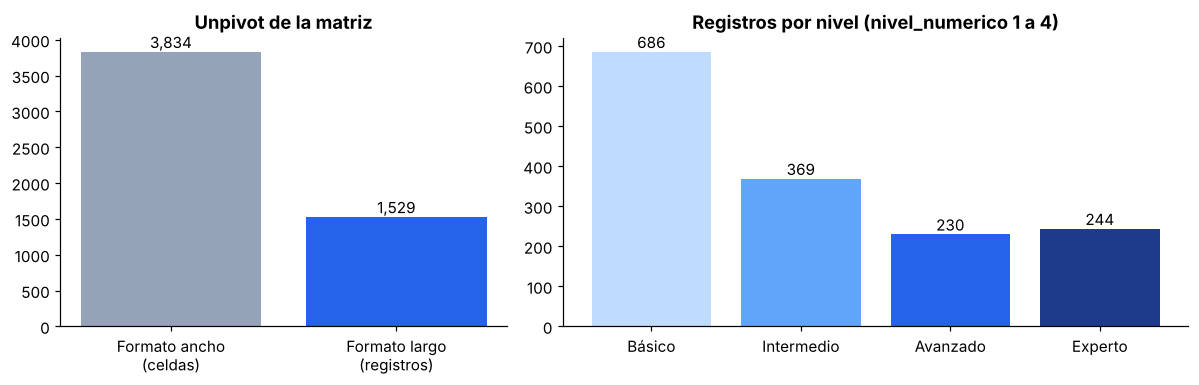

Control: clean_matriz_habilidades.csv tiene 1,000 filas; el unpivot completo da 1,529.
Si el CSV tiene 1,000 filas, se exportó con el límite por defecto de MySQL Workbench y hay que volver a exportarlo.


In [8]:
hab_cols = list(matriz.columns[6:])   # las 71 columnas de habilidad
largo = (matriz.melt(id_vars=['ID Colaborador', 'Estatus'], value_vars=hab_cols, var_name='habilidad', value_name='nivel')
               .dropna(subset=['nivel']))
largo['nivel'] = largo['nivel'].astype(str).str.strip()
largo = largo[largo.nivel != '']
largo['codigo'] = largo.habilidad.astype(str).str.strip().str[:5].str.upper()
NIVEL = {'Básico': 1, 'Intermedio': 2, 'Avanzado': 3, 'Experto': 4}
largo['nivel_numerico'] = largo.nivel.map(NIVEL)

print(f'Antes: {matriz.shape[0]} filas × {matriz.shape[1]} columnas = {matriz.shape[0]*len(hab_cols):,} celdas de habilidad')
print(f'Después: {len(largo):,} registros (colaborador, habilidad, nivel)')
conteo = largo.nivel.value_counts().reindex(NIVEL)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={'width_ratios': [1, 1.4]})
ax[0].bar(['Formato ancho\n(celdas)', 'Formato largo\n(registros)'], [matriz.shape[0]*len(hab_cols), len(largo)], color=[GRIS, AZUL])
ax[0].set_title('Unpivot de la matriz')
for x, v in enumerate([matriz.shape[0]*len(hab_cols), len(largo)]): ax[0].text(x, v, f'{v:,}', ha='center', va='bottom')
ax[1].bar(conteo.index, conteo.values, color=['#bfdbfe', '#60a5fa', '#2563eb', '#1e3a8a'])
for x, v in enumerate(conteo.values): ax[1].text(x, v, f'{v}', ha='center', va='bottom')
ax[1].set_title('Registros por nivel (nivel_numerico 1 a 4)')
guardar(fig, '06_unpivot_matriz')

csv = leer_clean('matriz_habilidades')
print(f'Control: clean_matriz_habilidades.csv tiene {len(csv):,} filas; el unpivot completo da {len(largo):,}.')
print('Si el CSV tiene 1,000 filas, se exportó con el límite por defecto de MySQL Workbench y hay que volver a exportarlo.')

## Etapa 3 · Indicadores calculados sobre las tablas acondicionadas
Atributos nuevos de la etapa 3: `costo_por_hora = sueldo_total_integrado / 160`, `estado_asignacion`,
`dias_para_finalizar`, `estado_vencimiento`, `nivel_numerico` y columnas `revision_*`.

In [9]:
c = clean['colaboradores']
activos = c[c.estatus == 'Activo']
sin_asig = activos[activos.estado_asignacion == 'Sin asignación registrada']
validos = sin_asig[sin_asig.revision_sueldo == 'Sin observaciones']
kpi = pd.Series({
    'Colaboradores activos': len(activos),
    'Con asignación registrada': (activos.estado_asignacion == 'Con asignación').sum(),
    'Sin asignación registrada': len(sin_asig),
    'Tasa de utilización (%)': round((activos.estado_asignacion == 'Con asignación').mean() * 100, 1),
    'Costo mensual sin asignación (MXN, parcial)': round(validos.sueldo_total_integrado.sum(), 0),
    'Sueldos que requieren revisión': (c.revision_sueldo == 'Requiere revisión').sum(),
    'Costo por hora mediano (MXN)': round(activos.costo_por_hora.median(), 1),
})
kpi.to_frame('valor')

,valor
Colaboradores activos,75.0
Con asignación registrada,30.0
Sin asignación registrada,45.0
Tasa de utilización (%),40.0
"Costo mensual sin asignación (MXN, parcial)",1994154.0
Sueldos que requieren revisión,25.0
Costo por hora mediano (MXN),329.1


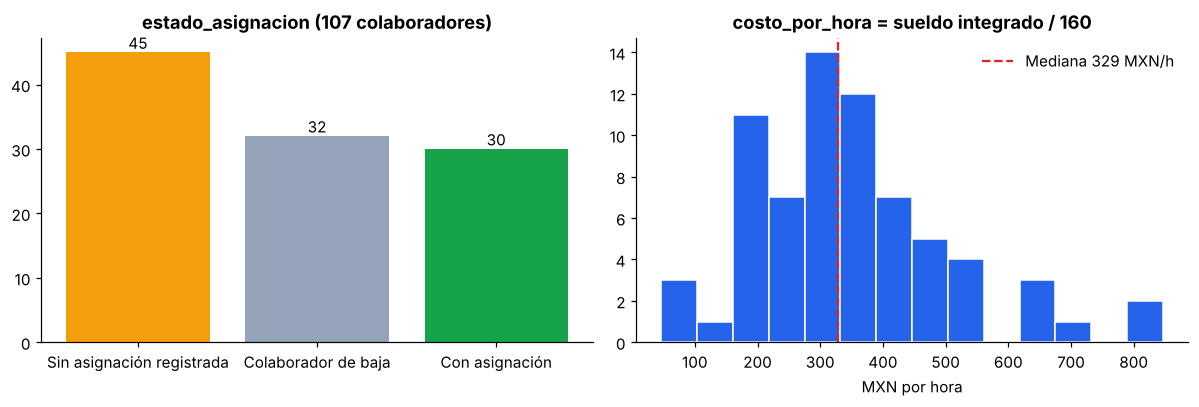

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ea = c.estado_asignacion.value_counts()
ax[0].bar(ea.index, ea.values, color=[AMBAR, GRIS, VERDE][:len(ea)])
for x, v in enumerate(ea.values): ax[0].text(x, v, v, ha='center', va='bottom')
ax[0].set_title('estado_asignacion (107 colaboradores)')
cph = activos.costo_por_hora.dropna(); cph = cph[cph > 0]
ax[1].hist(cph, bins=14, color=AZUL, edgecolor='white')
ax[1].axvline(cph.median(), color=ROJO, ls='--', lw=1.5, label=f'Mediana {cph.median():,.0f} MXN/h')
ax[1].set_title('costo_por_hora = sueldo integrado / 160'); ax[1].set_xlabel('MXN por hora'); ax[1].legend(frameon=False)
guardar(fig, '07_asignacion_y_costo_hora')

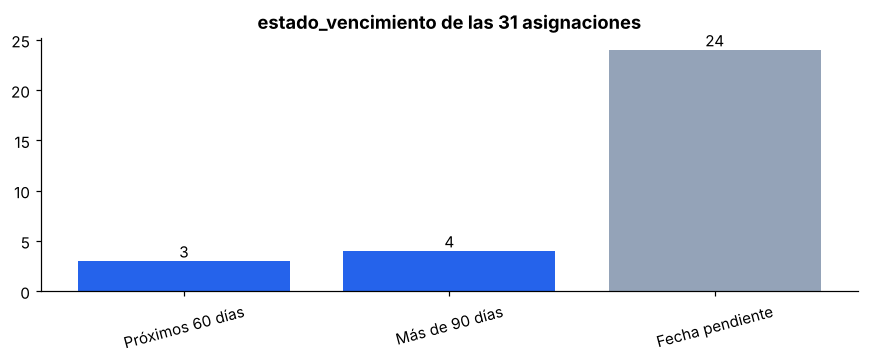

In [11]:
a = clean['asignaciones']
orden = ['Vencida', 'Próximos 30 días', 'Próximos 60 días', 'Próximos 90 días', 'Más de 90 días', 'Fecha pendiente']
ev = a.estado_vencimiento.value_counts()
ev = ev.reindex([o for o in orden if o in ev.index] + [i for i in ev.index if i not in orden])
colores = {'Vencida': ROJO, 'Fecha pendiente': GRIS}
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(ev.index, ev.values, color=[colores.get(i, AZUL) for i in ev.index])
for x, v in enumerate(ev.values): ax.text(x, v, v, ha='center', va='bottom')
ax.set_title('estado_vencimiento de las 31 asignaciones'); plt.xticks(rotation=15)
guardar(fig, '08_vencimientos')

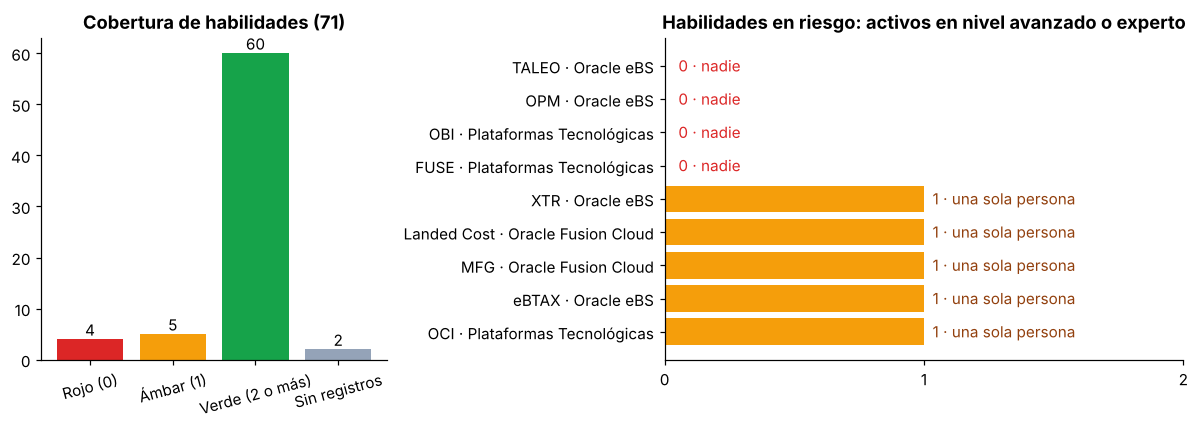

,codigo,descripcion,tecnologia,especialistas
26,H0028,TALEO,Oracle eBS,0
21,H0023,OPM,Oracle eBS,0
47,H0049,OBI,Plataformas Tecnológicas,0
60,H0062,FUSE,Plataformas Tecnológicas,0
5,H0007,XTR,Oracle eBS,1
41,H0043,Landed Cost,Oracle Fusion Cloud,1
43,H0045,MFG,Oracle Fusion Cloud,1
6,H0008,eBTAX,Oracle eBS,1
48,H0050,OCI,Plataformas Tecnológicas,1


In [12]:
act_ids = set(clean['colaboradores'].query("estatus == 'Activo'").id)
especialistas = largo[largo.ID_Colaborador.isin(act_ids) & (largo.nivel_numerico >= 3)] if 'ID_Colaborador' in largo else \
                largo[largo['ID Colaborador'].isin(act_ids) & (largo.nivel_numerico >= 3)]
cat = clean['habilidades'].copy()
cat['especialistas'] = cat.codigo.map(especialistas.groupby('codigo').size()).fillna(0).astype(int)
con_reg = set(largo.codigo)
cat['semaforo'] = np.select([~cat.codigo.isin(con_reg), cat.especialistas == 0, cat.especialistas == 1],
                            ['Sin registros', 'Rojo (0)', 'Ámbar (1)'], 'Verde (2 o más)')
sem = cat.semaforo.value_counts().reindex(['Rojo (0)', 'Ámbar (1)', 'Verde (2 o más)', 'Sin registros']).fillna(0)

fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios': [1, 1.5]})
ax[0].bar(sem.index, sem.values, color=[ROJO, AMBAR, VERDE, GRIS])
for x, v in enumerate(sem.values): ax[0].text(x, v, int(v), ha='center', va='bottom')
ax[0].set_title('Cobertura de habilidades (71)'); ax[0].tick_params(axis='x', rotation=15)
riesgo = cat[cat.semaforo.isin(['Rojo (0)', 'Ámbar (1)'])].sort_values('especialistas')
ax[1].barh(riesgo.descripcion + ' · ' + riesgo.tecnologia, riesgo.especialistas,
           color=[ROJO if v == 0 else AMBAR for v in riesgo.especialistas])
for y, v in enumerate(riesgo.especialistas):
    ax[1].text(max(v, 0.02), y, '  0 · nadie' if v == 0 else '  1 · una sola persona', va='center',
               color=ROJO if v == 0 else '#92400e')
ax[1].set_xlim(0, 2); ax[1].set_xticks([0, 1, 2]); ax[1].invert_yaxis()
ax[1].set_title('Habilidades en riesgo: activos en nivel avanzado o experto')
guardar(fig, '09_cobertura_habilidades')
riesgo[['codigo', 'descripcion', 'tecnologia', 'especialistas']]

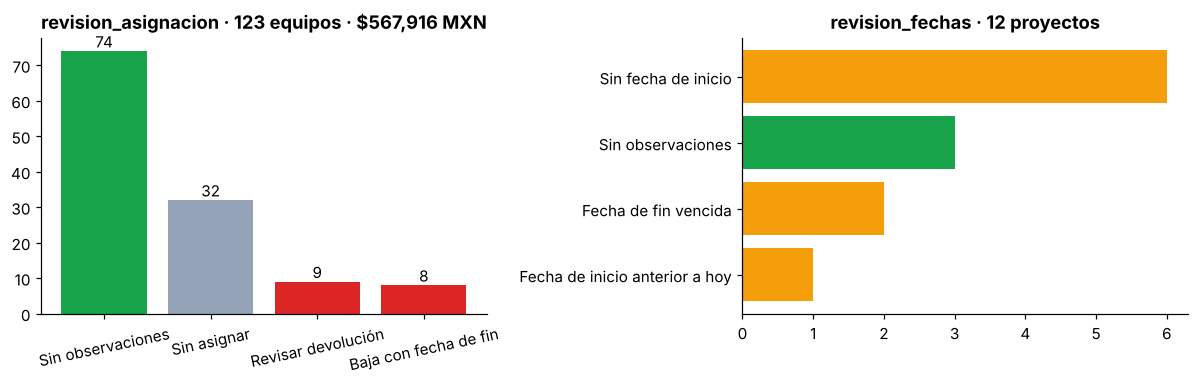

In [13]:
ac = clean['activos']
ra = ac.revision_asignacion.value_counts()
cl = clean['clientes']
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(ra.index, ra.values, color=[VERDE if i == 'Sin observaciones' else (GRIS if i == 'Sin asignar' else ROJO) for i in ra.index])
for x, v in enumerate(ra.values): ax[0].text(x, v, v, ha='center', va='bottom')
ax[0].set_title(f'revision_asignacion · 123 equipos · ${ac.costo.sum():,.0f} MXN'); ax[0].tick_params(axis='x', rotation=12)
rf = cl.revision_fechas.value_counts()
ax[1].barh(rf.index, rf.values, color=[VERDE if i == 'Sin observaciones' else AMBAR for i in rf.index])
ax[1].set_title('revision_fechas · 12 proyectos'); ax[1].invert_yaxis()
guardar(fig, '10_activos_y_proyectos')

## Etapa 4 · Modelo dimensional lógico (Kimball)
**Constelación de hechos** con tres tablas de hechos y siete dimensiones. `Dim_Colaborador` es una dimensión
**conformada** (la comparten los tres hechos) y `Dim_Tiempo` es de **rol múltiple** (fecha de inicio y de fin).

| Hecho | Granularidad | Registros | Métrica |
| --- | --- | --- | --- |
| Fact_Asignacion | un colaborador en un proyecto | 31 | dias_para_finalizar |
| Fact_Habilidad_Colaborador | un colaborador en una habilidad | 1,529 | nivel_numerico |
| Fact_Activo | un equipo y quien lo tiene | 123 | costo |

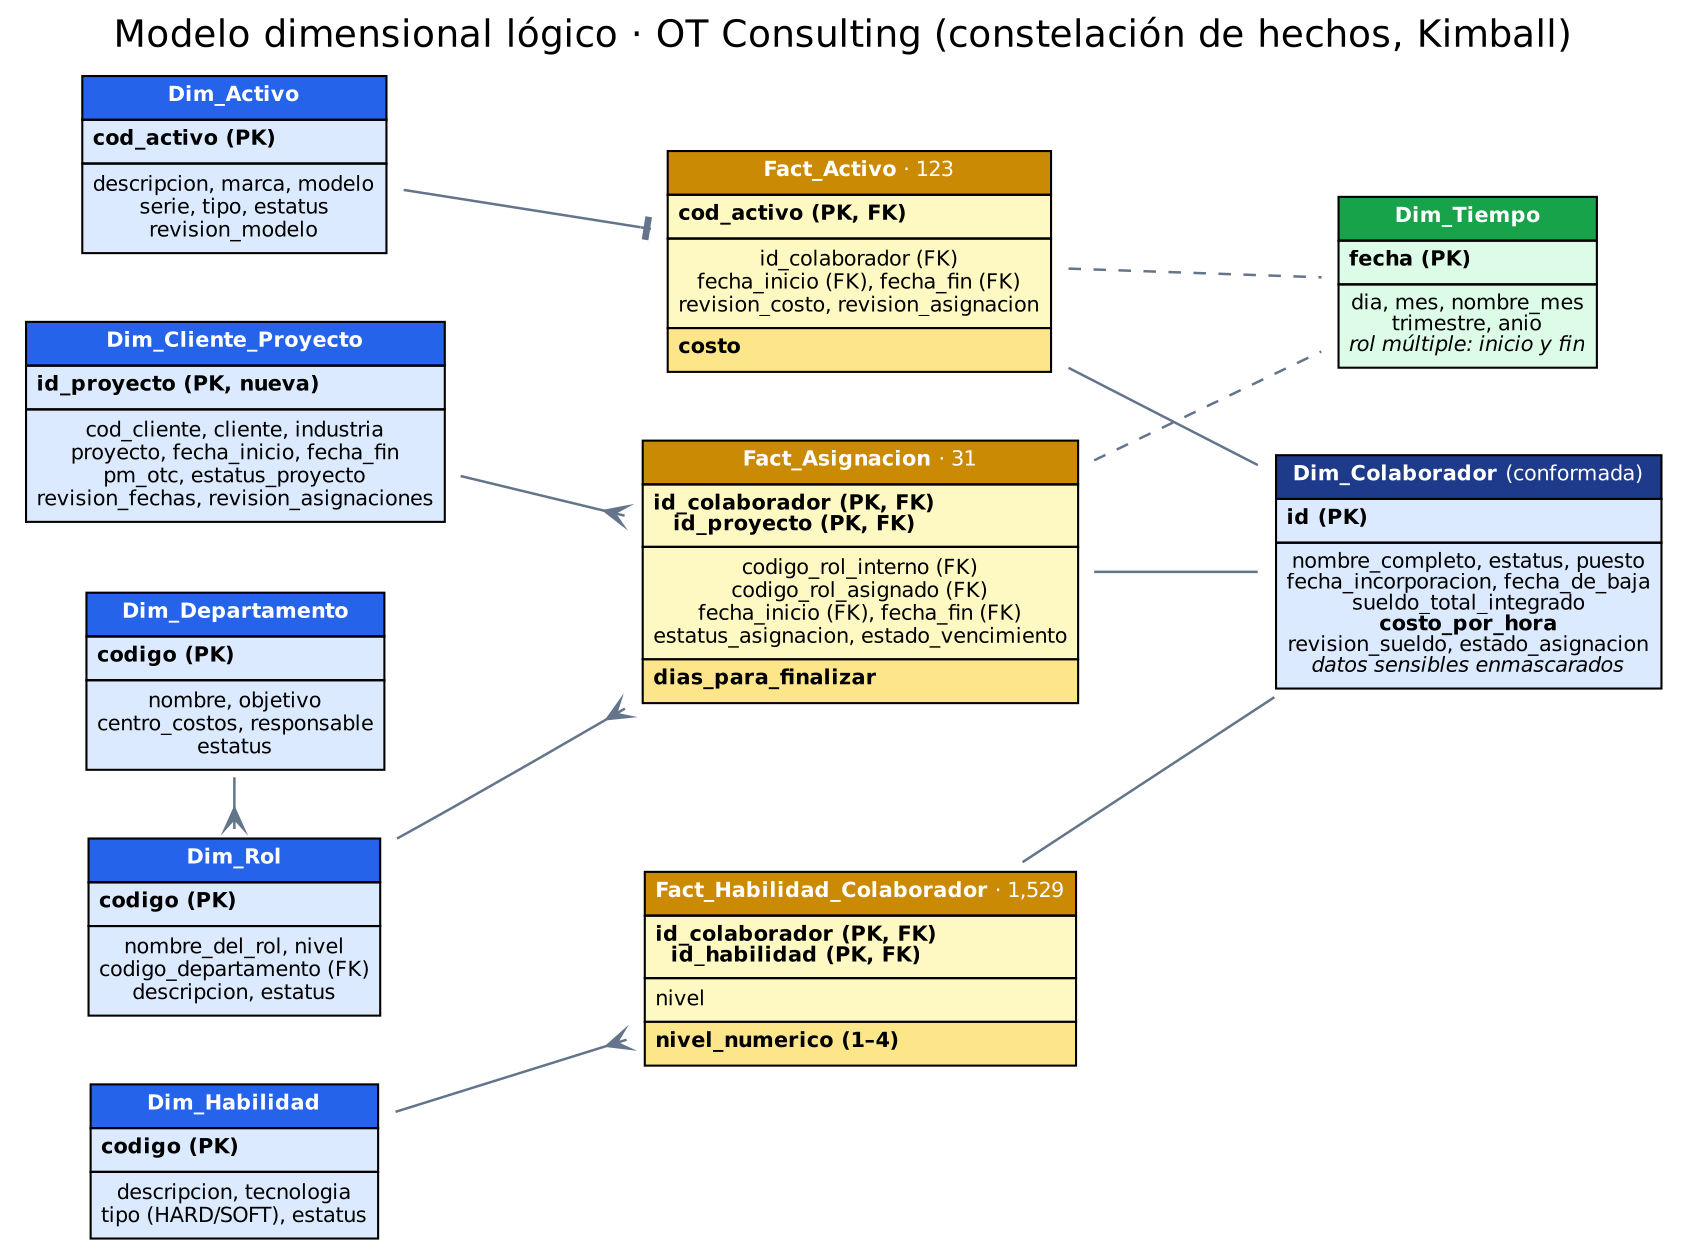

In [14]:
from IPython.display import Image
Image(filename=str(IMG / 'modelo_dimensional.png'))

```mermaid
erDiagram
    Dim_Colaborador ||--o{ Fact_Asignacion : id_colaborador
    Dim_Colaborador ||--o{ Fact_Habilidad_Colaborador : id_colaborador
    Dim_Colaborador ||--o{ Fact_Activo : id_colaborador
    Dim_Cliente_Proyecto ||--o{ Fact_Asignacion : id_proyecto
    Dim_Rol ||--o{ Fact_Asignacion : codigo_rol
    Dim_Departamento ||--o{ Dim_Rol : codigo_departamento
    Dim_Habilidad ||--o{ Fact_Habilidad_Colaborador : id_habilidad
    Dim_Activo ||--|| Fact_Activo : cod_activo
    Dim_Tiempo ||--o{ Fact_Asignacion : fecha_inicio_fin
    Dim_Tiempo ||--o{ Fact_Activo : fecha_inicio_fin
```

## Cómo responde el modelo a las preguntas detonadoras

| Pregunta | Tablas del modelo | Evidencia en este cuaderno |
| --- | --- | --- |
| 1. ¿Quién termina pronto una asignación? | Fact_Asignacion + Dim_Tiempo | estado_vencimiento |
| 2. ¿Quién no tiene proyecto? | Dim_Colaborador (estado_asignacion) | 45 sin asignación registrada |
| 3. ¿Costo por hora de cada colaborador? | Dim_Colaborador (costo_por_hora) | histograma de costo/h |
| 4. ¿Cuánto cuesta tener gente sin asignación? | Dim_Colaborador | costo mensual parcial |
| 5. ¿Quién tiene las habilidades y estará a tiempo? | Fact_Habilidad_Colaborador + Dim_Habilidad + Fact_Asignacion | semáforo de cobertura |
| 6. ¿En qué fase va cada proyecto? | Dim_Cliente_Proyecto | revision_fechas (no hay fases: dato faltante) |
| 7. ¿Equipos con personas dadas de baja? | Fact_Activo + Dim_Colaborador | revision_asignacion |